# BIOMASS tomogram — 2D visualisation

This notebook opens a small real L2A subset, prepares explicit power and vertical-structure variables, and displays height bands, ecological scattering proxies, and a vertical curtain. Heights are relative tomographic heights; the derived metrics are scattering-structure descriptors, not direct canopy height or biomass measurements.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

project_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tomo_canopy').is_dir() and (p / 'data').is_dir())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from tomo_canopy.cubegen import cube_from_layers
from tomo_canopy.processors import TomogramProcessor
from tomo_canopy.providers import TomogramProvider
from tomo_canopy.transforms import match_vertical_resolution
from tomo_canopy.visualisation import CanopyViewer

plt.style.use('seaborn-v0_8-whitegrid')

## Open and prepare a small Lope subset

In [2]:
plot_lon, plot_lat = 11.5730, -0.1750
delta = 0.006
bounds = (plot_lon - delta, plot_lat - delta, plot_lon + delta, plot_lat + delta)
tom_source = next((project_root / 'data' / 'TOM').glob('*L2A*'))

tom = TomogramProvider().open(
    tom_source,
    polarization='HV',
    height_range=(-20, 80),
    bounds=bounds,
)
processor = TomogramProcessor()
powered = processor.to_power(tom)
resolution_matched = match_vertical_resolution(
    powered, target_resolution=20.0, variables=['tomographic_power']
)
peak_power = float(resolution_matched.tomographic_power.max().compute())
prepared = processor.to_db(
    resolution_matched, variable='tomographic_power',
    reference=peak_power, floor_db=-35.0,
)
prepared = processor.integrate_vertical_bands(prepared, band_size=20.0)
prepared = processor.add_vertical_metrics(prepared, upper_height=40.0)
layer = processor.to_data_layer(prepared, name='lope_tomogram')
cube = cube_from_layers([layer])
viewer = CanopyViewer(cube)
prepared

<xarray.Dataset> Size: 953kB
Dimensions:                         (polarization: 1, z: 51, y: 29, x: 29,
                                     height_band: 6)
Coordinates:
  * polarization                    (polarization) <U2 8B 'HV'
  * z                               (z) float64 408B -20.0 -18.0 ... 78.0 80.0
  * y                               (y) float64 232B -0.1809 -0.1804 ... -0.1692
  * x                               (x) float64 232B 11.57 11.57 ... 11.58 11.58
  * height_band                     (height_band) float64 48B -20.0 0.0 ... 80.0
Data variables:
    tomographic_cube                (polarization, z, y, x) float32 172kB dask.array<chunksize=(1, 14, 29, 29), meta=np.ndarray>
    tomographic_power               (polarization, z, y, x) float64 343kB dask.array<chunksize=(1, 48, 3, 3), meta=np.ndarray>
    tomographic_power_db            (polarization, z, y, x) float64 343kB dask.array<chunksize=(1, 48, 3, 3), meta=np.ndarray>
    vertical_contribution           (polarization, height_band, y, x) float64 40kB dask.array<chunksize=(1, 1, 3, 3), meta=np.ndarray>
    tomographic_power_column_total  (polarization, y, x) float64 7kB dask.array<chunksize=(1, 3, 3), meta=np.ndarray>
    scattering_height_50            (polarization, y, x) float64 7kB dask.array<chunksize=(1, 3, 3), meta=np.ndarray>
    scattering_height_90            (polarization, y, x) float64 7kB dask.array<chunksize=(1, 3, 3), meta=np.ndarray>
    scattering_centroid             (polarization, y, x) float64 7kB dask.array<chunksize=(1, 3, 3), meta=np.ndarray>
    dominant_scattering_height      (polarization, y, x) float64 7kB dask.array<chunksize=(1, 3, 3), meta=np.ndarray>
    dominant_contribution           (polarization, y, x) float64 7kB dask.array<chunksize=(1, 3, 3), meta=np.ndarray>
    vertical_entropy                (polarization, y, x) float64 7kB dask.array<chunksize=(1, 3, 3), meta=np.ndarray>
    upper_contribution              (polarization, y, x) float64 7kB dask.array<chunksize=(1, 3, 3), meta=np.ndarray>
Attributes: (12/25)
    coordinate_normalization:      XML latitude/longitude field semantics; ST...
    source:                        /home/simon/Documents/science/GFZ/projects...
    product_root:                  /home/simon/Documents/science/GFZ/projects...
    product_id:                    BIO_TP_TOM_L2A_20251007T050300_20251022T05...
    product_level:                 L2A
    modality:                      tomogram
    ...                            ...
    vertical_resolution_units:     m
    source_vertical_resolution:    0.0
    resolution_kernel:             gaussian_fwhm
    decibel_floor:                 -35.0
    vertical_structure_band_size:  20.0
    upper_contribution_height:     40.0

## Normalized vertical contribution by 20 m band

Each panel shows the fraction of a horizontal column's total power assigned to that height band. The fractions sum to one within valid columns, so absolute scattering strength is intentionally removed.

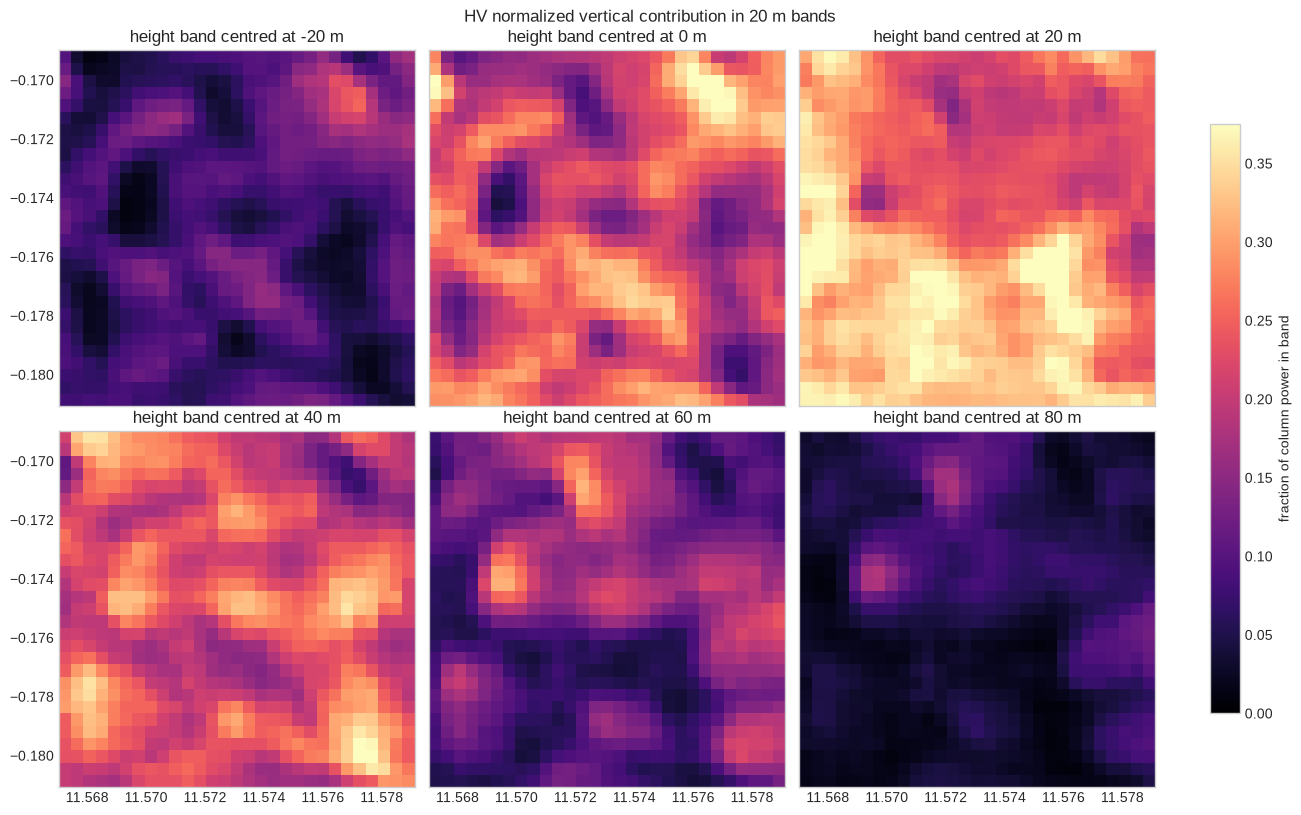

In [3]:
fig, axes = viewer.tomogram_bands(
    layer='lope_tomogram', polarization='HV'
)
fig.suptitle('HV normalized vertical contribution in 20 m bands')
plt.show()

## Scattering-structure metric maps

Read these comparatively. In particular, `upper_contribution` is the fraction at or above 40 m; `upper_height=40` did not crop the displayed volume.

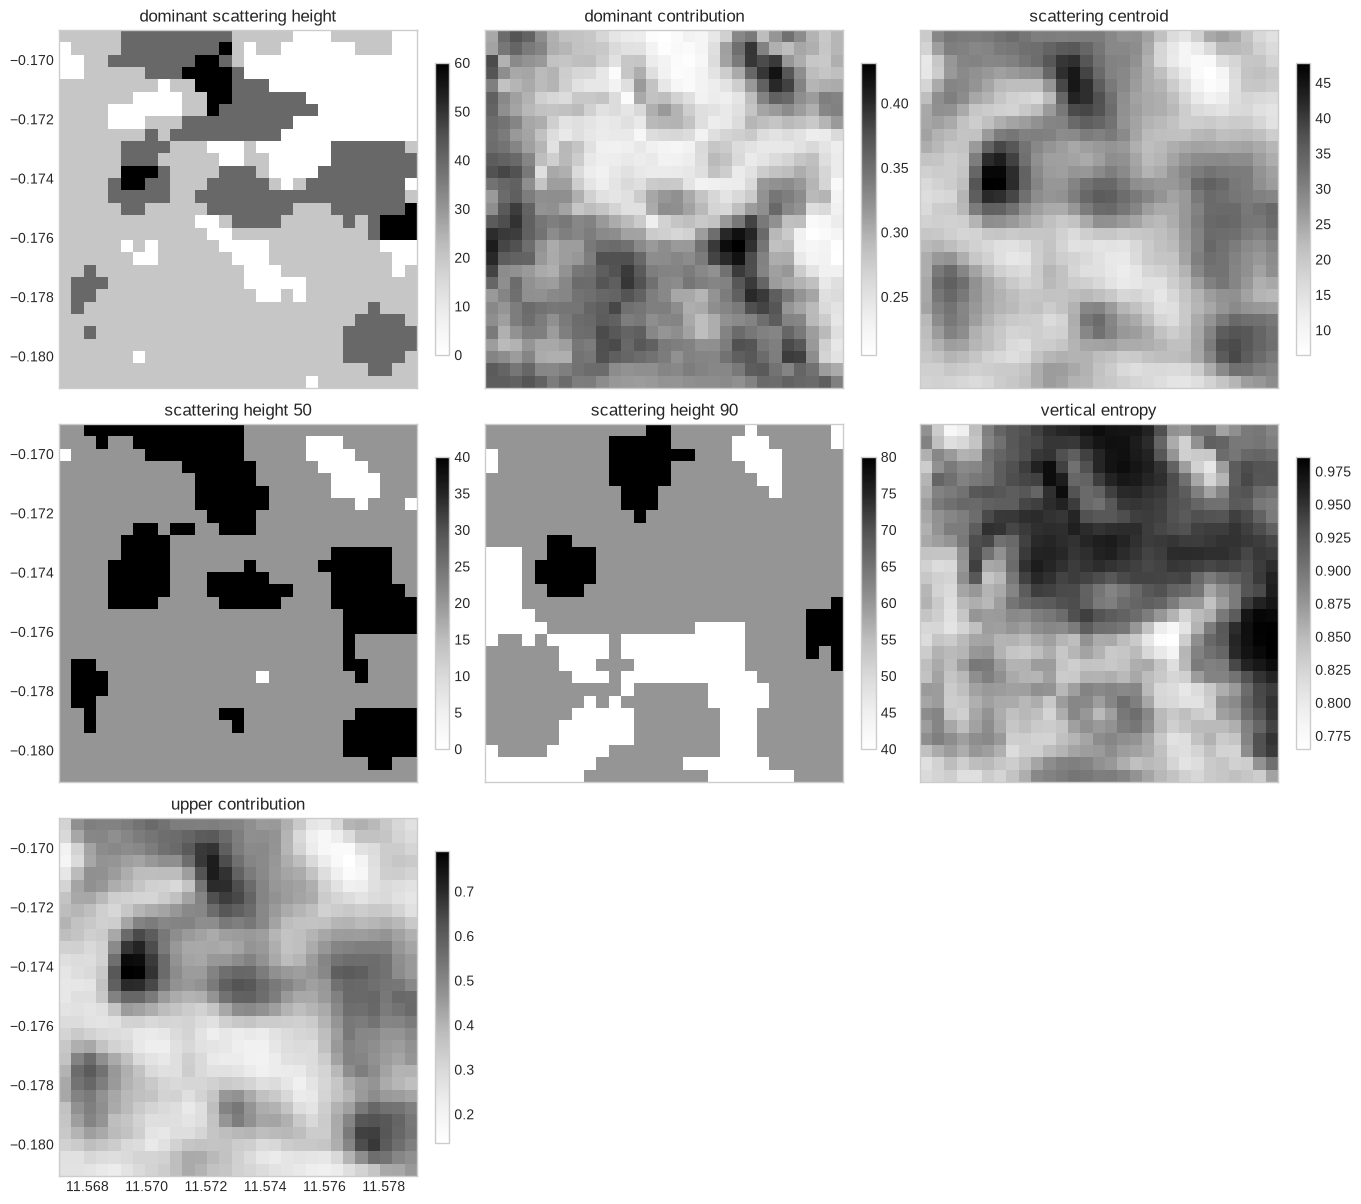

In [4]:
fig, axes = viewer.tomogram_metrics(
    layer='lope_tomogram',
    polarization='HV',
    metrics=[
        'dominant_scattering_height',
        'dominant_contribution',
        'scattering_centroid',
        'scattering_height_50',
        'scattering_height_90',
        'vertical_entropy',
        'upper_contribution',
    ],
)
plt.show()

## Vertical tomogram slice

The slice is selected at the nearest longitude. Its short, wide figure shape is a display choice; `height_range` controls the displayed data interval independently.

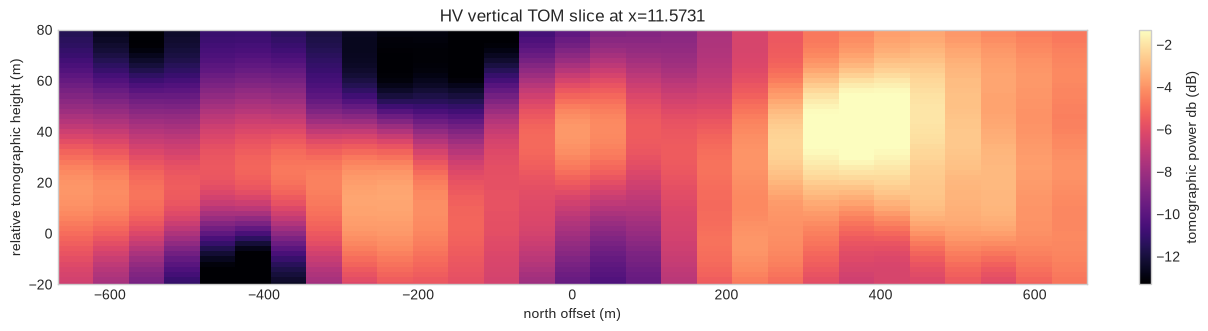

In [ ]:
fig, ax = viewer.tomogram_vertical_slice(
    layer='lope_tomogram',
    variable='tomographic_power_db',
    polarization='HV',
    axis='x',
    coordinate=plot_lon,
    height_range=(0, 80),
    figsize=(12, 3.2),
)
plt.show()